<a href="https://colab.research.google.com/github/Luoxiaowanzi/Class/blob/main/Acctg_5150_Lab_HW_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc)
import matplotlib.pyplot as plt


In [2]:

df = pd.read_csv('ar_default_data.csv')


In [3]:

df.head()


,bad_ar,gender,education,marital_status,age_decile,outstanding_balance,pay_this_month,no_activity_this_month,last_payment_portion,num_recent_payments,credit_limit
0,1,female,2-university,married,20,0.03913,2,0,1.000000,1,0.2
1,1,female,2-university,single,20,0.02682,0,0,0.372856,4,1.2
2,0,female,2-university,single,30,0.27721,0,0,0.108220,6,0.9
3,0,female,2-university,married,30,0.44990,0,0,0.041465,6,0.5
4,0,male,2-university,married,50,0.06617,0,0,0.352734,6,0.5


In [4]:

df['bad_ar'].value_counts(normalize=True)


,proportion
bad_ar,
0,0.778354
1,0.221646


In [5]:

model_base = smf.logit(
    'bad_ar ~ credit_limit + outstanding_balance + pay_this_month + no_activity_this_month + last_payment_portion + num_recent_payments',
    data=df
).fit()

print(model_base.summary())


Optimization terminated successfully.
         Current function value: 0.446830
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                 bad_ar   No. Observations:                29881
Model:                          Logit   Df Residuals:                    29874
Method:                           MLE   Df Model:                            6
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.1553
Time:                        01:28:28   Log-Likelihood:                -13352.
converged:                       True   LL-Null:                       -15807.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.8178      0.052    -15.759      0.000      -0.919      

In [6]:

THRESHOLD = 0.5

df['prob_base'] = model_base.predict(df)
df['pred_base'] = (df['prob_base'] >= THRESHOLD).astype(int)


In [7]:

df[['bad_ar', 'prob_base', 'pred_base']].head()


,bad_ar,prob_base,pred_base
0,1,0.739398,1
1,1,0.158910,0
2,0,0.141814,0
3,0,0.156751,0
4,0,0.145376,0


In [8]:

confusion_matrix(df['bad_ar'], df['pred_base'])


array([[22222,  1036],
       [ 4404,  2219]])

In [9]:

print("Accuracy:", accuracy_score(df['bad_ar'], df['pred_base']))
print("Precision:", precision_score(df['bad_ar'], df['pred_base']))
print("Recall:", recall_score(df['bad_ar'], df['pred_base']))
print("F1 Score:", f1_score(df['bad_ar'], df['pred_base']))


Accuracy: 0.8179445132358355
Precision: 0.6817204301075269
Recall: 0.3350445417484524
F1 Score: 0.44928123101842476


In [10]:

model_demo = smf.logit(
    'bad_ar ~ credit_limit + outstanding_balance + pay_this_month + no_activity_this_month + last_payment_portion + num_recent_payments + C(gender) + C(education) + C(marital_status) + C(age_decile)',
    data=df
).fit()

print(model_demo.summary())


Optimization terminated successfully.
         Current function value: 0.444658
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 bad_ar   No. Observations:                29881
Model:                          Logit   Df Residuals:                    29862
Method:                           MLE   Df Model:                           18
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.1594
Time:                        01:32:25   Log-Likelihood:                -13287.
converged:                       True   LL-Null:                       -15807.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -0.8322      0.156     -5

In [11]:

rows = []

for threshold in np.arange(0, 1.01, 0.01):
    predictions = (df['prob_base'] >= threshold).astype(int)

    precision = precision_score(df['bad_ar'], predictions, zero_division=0)
    recall = recall_score(df['bad_ar'], predictions)

    rows.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall
    })

threshold_df = pd.DataFrame(rows)

threshold_df.head()


,Threshold,Precision,Recall
0,0.00,0.221646,1.0
1,0.01,0.221646,1.0
2,0.02,0.221646,1.0
3,0.03,0.221661,1.0
4,0.04,0.221727,1.0


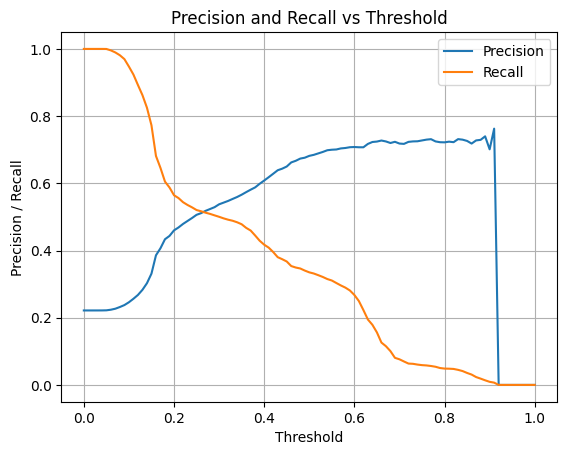

In [12]:

plt.plot(threshold_df['Threshold'], threshold_df['Precision'], label='Precision')
plt.plot(threshold_df['Threshold'], threshold_df['Recall'], label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Precision / Recall')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()


In [13]:

fpr, tpr, thresholds = roc_curve(df['bad_ar'], df['prob_base'])

auc_base = auc(fpr, tpr)

print("AUC:", auc_base)


AUC: 0.7516360244561894


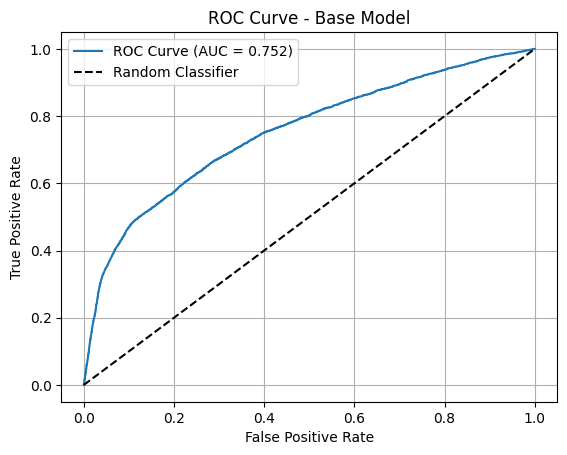

In [14]:

plt.plot(fpr, tpr, label='ROC Curve (AUC = {:.3f})'.format(auc_base))
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Base Model')
plt.legend()
plt.grid(True)
plt.show()


In [15]:

rows = []

for threshold in np.arange(0, 1.01, 0.01):
    predictions = (df['prob_base'] >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        df['bad_ar'], predictions
    ).ravel()

    net = tp * 0.4 - fp * 0.5 - fn * 0.4

    rows.append({
        'Threshold': threshold,
        'Expected Cost': net
    })

cost_df = pd.DataFrame(rows)

cost_df.head()


,Threshold,Expected Cost
0,0.00,-8979.8
1,0.01,-8979.8
2,0.02,-8979.8
3,0.03,-8978.8
4,0.04,-8974.3


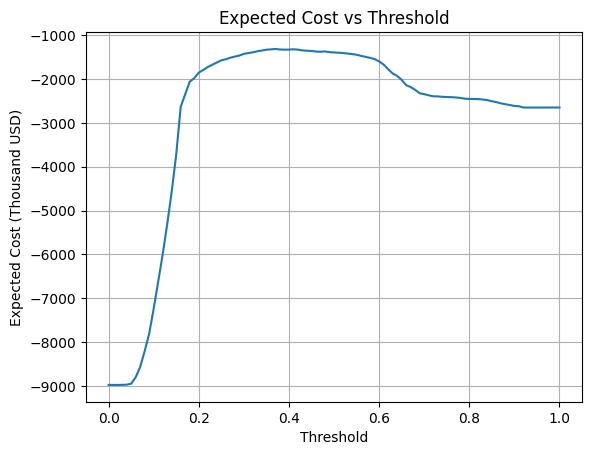

In [16]:

plt.plot(cost_df['Threshold'], cost_df['Expected Cost'])

plt.xlabel('Threshold')
plt.ylabel('Expected Cost (Thousand USD)')
plt.title('Expected Cost vs Threshold')
plt.grid(True)
plt.show()


In [20]:
THRESHOLD = 0.5

df['prob_demo'] = model_demo.predict(df)
df['pred_demo'] = (df['prob_demo'] >= THRESHOLD).astype(int)

In [21]:
accuracy_base = accuracy_score(df['bad_ar'], df['pred_base'])
accuracy_demo = accuracy_score(df['bad_ar'], df['pred_demo'])

print("Base Model Accuracy:", accuracy_base)
print("Demographics Model Accuracy:", accuracy_demo)
print("Improvement:", (accuracy_demo - accuracy_base) * 100)

Base Model Accuracy: 0.8179445132358355
Demographics Model Accuracy: 0.8183461062213446
Improvement: 0.04015929855091249


In [22]:

print("Base Precision:", precision_score(df['bad_ar'], df['pred_base']))
print("Demo Precision:", precision_score(df['bad_ar'], df['pred_demo']))

print("Base Recall:", recall_score(df['bad_ar'], df['pred_base']))
print("Demo Recall:", recall_score(df['bad_ar'], df['pred_demo']))


Base Precision: 0.6817204301075269
Demo Precision: 0.6819981724032896
Base Recall: 0.3350445417484524
Demo Recall: 0.3380643213045448


In [23]:

result = threshold_df[threshold_df['Recall'] >= 0.80]

best = result.iloc[-1]

print("Threshold:", best['Threshold'])
print("Precision:", best['Precision'])
print("Recall:", best['Recall'])

predictions = (df['prob_base'] >= best['Threshold']).astype(int)
print("Customers Flagged:", predictions.sum())


Threshold: 0.14
Precision: 0.30273145326610895
Recall: 0.8250037747244451
Customers Flagged: 18049


In [24]:

best_row = cost_df.loc[cost_df['Expected Cost'].idxmax()]

print("Optimal Threshold:", best_row['Threshold'])
print("Maximum Net Result:", best_row['Expected Cost'])

print(cost_df[np.isclose(cost_df['Threshold'], 0.5)])


Optimal Threshold: 0.37
Maximum Net Result: -1311.8
    Threshold  Expected Cost
50        0.5        -1392.0


In [25]:

pred_optimal = (df['prob_base'] >= 0.37).astype(int)

print("Optimal Precision:", precision_score(df['bad_ar'], pred_optimal))
print("Optimal Recall:", recall_score(df['bad_ar'], pred_optimal))

print("Default Precision:", precision_score(df['bad_ar'], df['pred_base']))
print("Default Recall:", recall_score(df['bad_ar'], df['pred_base']))


Optimal Precision: 0.5810578575520337
Optimal Recall: 0.4594594594594595
Default Precision: 0.6817204301075269
Default Recall: 0.3350445417484524


In [26]:

rows = []

for threshold in np.arange(0, 1.01, 0.01):
    predictions = (df['prob_base'] >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        df['bad_ar'], predictions
    ).ravel()

    net = tp * 0.4 - fp * 0.5 - fn * 0.8

    rows.append({
        'Threshold': threshold,
        'Net Result': net
    })

new_cost_df = pd.DataFrame(rows)

best = new_cost_df.loc[new_cost_df['Net Result'].idxmax()]

print("New Optimal Threshold:", best['Threshold'])
print("New Net Result:", best['Net Result'])


New Optimal Threshold: 0.35000000000000003
New Net Result: -2711.5
